In [35]:
import pandas as pd
import numpy as np
from scipy.optimize import minimize
import matplotlib.pyplot as plt




In [36]:
df = pd.read_csv("bird_count.csv")
x_yr = [df["yr"]-2000]
y_count = df["count"]
df.describe()


,count,yr,observerAge,lineCov
count,13.000000,13.000000,13.000000,13.000000
mean,8.307692,2005.692308,51.384615,0.991667
std,3.660251,4.289223,15.992386,0.005103
min,2.000000,1999.000000,27.000000,0.987500
25%,5.000000,2002.000000,30.000000,0.987500
50%,9.000000,2006.000000,60.000000,0.991667
75%,12.000000,2009.000000,63.000000,0.991667
max,14.000000,2012.000000,64.000000,1.000000


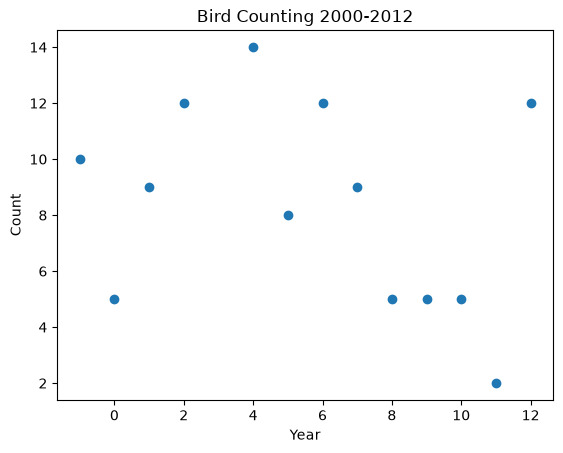

In [37]:
plt.scatter(x_yr,y_count)
plt.title("Bird Counting 2000-2012")
plt.xlabel("Year")
plt.ylabel("Count")

plt.show()

In [38]:
def poisson_dis (param, x, y):
    beta0,beta1 = param[0],param[1]
    log_lamda = beta0+beta1* np.array(x)
    log_llh = np.sum((-np.exp(log_lamda))+(log_lamda)*np.array(y)) #here factorial y not contain parameters, likelyhood can be optimized without term y
    return -log_llh

'''beta0 and beta1 are parameters have to be optimized to maximum the likelihood
In this case, minimizing the -log_llh can be applied
Start from beta0 and beta1 are both 0'''

initial_theta = [0,0]
est = minimize(poisson_dis, initial_theta, args=(x_yr,y_count))
theta_est = est.x
beta0_est,beta1_est = theta_est[0],theta_est[1]

print(f'Estimated beta1:{beta1_est: .5f}')
print(est.success)

Estimated beta1:-0.03244
True


In [39]:
random = np.random.default_rng(42)
B = 1000
beta1_boot = np.empty(B)
n_fial = 0
n = len(x_yr)

x_arr = np.array(x_yr).ravel()
y_arr = np. array(y_count) .ravel()


for b in range(B):
    index = random.integers(0, 13, size = 13)
    est = minimize(poisson_dis,theta_est, args = (x_arr[index],y_arr[index]))
    beta1_boot[b] = est.x[1]

se = beta1_boot.std(ddof=1)
ci = np.percentile(beta1_boot, [2.5, 97.5])
print(f"Bootstrap SE of beta1: {se:.5f}")
print(f"95% percentile CI: [{ci[0]:.5f}, {ci[1]:.5f}]")



Bootstrap SE of beta1: 0.03555
95% percentile CI: [-0.11524, 0.02482]


The standard error of 0.0356 for $\hat\beta_1$ (B = 5000, seed 42), the difference is due to Monte Carlo variation, since the bootstrap samples are drawn randomly.